#### Import Libraries

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from factor_analyzer import Rotator
from sklearn.metrics import silhouette_score
import geopandas as gpd
from sklearn_extra.cluster import CLARA
from sklearn.cluster import MiniBatchKMeans
from sqlalchemy import text, create_engine

#### Create the connection with the DB (optional)

In [2]:
# Step 1: Create the connection with the DB
engine = create_engine("postgresql://urbaninfo:@cirrus.ita.chalmers.se/emc2_15mc")
conn = engine.connect()

#### Create schema (when its necessary)

In [3]:
# Create a new schema when it is necessary
#conn.execute(text('''CREATE SCHEMA IF NOT EXISTS s7_paper_foreground_street_networks'''))
#conn.commit()

### Import Data

In [4]:
# Import data
# In the case of this project we are using the street network of 5 European cities
# Gothenburg - SWE
got_nms_query = text('SELECT * FROM s7_paper_foreground_street_networks."2_segment_nms_got_nonzeros_EPSG3857"')
got_nms = gpd.read_postgis(got_nms_query, engine, geom_col='geometry')

# Turano - ITA
ver_nms_query = text('''SELECT * FROM s7_paper_foreground_street_networks."2_segment_nms_ver_nonzeros_EPSG3857"''')
ver_nms = gpd.read_postgis(ver_nms_query, engine, geom_col='geometry')

# Nice - FRA
nic_nms_query = text('''SELECT * FROM s7_paper_foreground_street_networks."2_segment_nms_nic_nonzeros_EPSG3857"''')
nic_nms = gpd.read_postgis(nic_nms_query, engine, geom_col='geometry')

# Nice - FRA
lil_nms_query = text('''SELECT * FROM s7_paper_foreground_street_networks."2_segment_nms_lil_nonzeros_EPSG3857"''')
lil_nms = gpd.read_postgis(lil_nms_query, engine, geom_col='geometry')

# Vienna - AUS
vie_nms_query = text('''SELECT * FROM s7_paper_foreground_street_networks."2_segment_nms_vie_nonzeros_EPSG3857"''')
vie_nms = gpd.read_postgis(vie_nms_query, engine, geom_col='geometry')


### Create the contextual corrected measure: Reach by Mean Betweenness

In [6]:
def create_ratio_columns(df, radius_values=[500, 1000, 1500, 2000, 2500, 3000, 3500, 4000, 4500, 5000]):
    # Convert numeric values to match column names (e.g., 1000 → '1k')
    radius_labels = {1000: '1k', 2000: '2k', 3000: '3k', 4000: '4k', 5000: '5k' }
    formatted_radii = [radius_labels.get(r, r) for r in radius_values]

    # Loop through the formatted radius values
    for radius in formatted_radii:
        abw_col = f'abw{radius}'
        ar_col = f'arw{radius}ab'
        rw_col = f'rw{radius}l'

        # Ensure all required columns exist
        if {abw_col, ar_col, rw_col}.issubset(df.columns):
            new_col_name = f'CB_MB_{radius}'
            df[new_col_name] = df[abw_col] / (df[ar_col]/ df[rw_col])

    return df


# Example usage
got_nms_norm_mbr = create_ratio_columns(got_nms).fillna(0)
nic_nms_norm_mbr = create_ratio_columns(nic_nms).fillna(0)
ver_nms_norm_mbr = create_ratio_columns(ver_nms).fillna(0)
lil_nms_norm_mbr = create_ratio_columns(lil_nms).fillna(0)
vie_nms_norm_mbr = create_ratio_columns(vie_nms).fillna(0)

## PCA analysis

#### Create the PCs, and test the variance

In [7]:
# Create a dictionary to concatenate the tables of the different cities
cities = {'Gothenburg': got_nms_norm_mbr, 'Versilia': ver_nms_norm_mbr,
          'Nice':nic_nms_norm_mbr, 'Lille':lil_nms_norm_mbr,
          'Vienna':vie_nms_norm_mbr}
# Display to check
print(cities)

{'Gothenburg':            fid                                           geometry      id  \
0            1  LINESTRING (1342159.842 7883580.812, 1342181.1...       1   
1            2  LINESTRING (1342169.171 7883499.833, 1342181.1...       2   
2            3  LINESTRING (1345950.739 7898301.149, 1345956.5...       3   
3            4  LINESTRING (1345947.221 7898257.083, 1345950.7...       4   
4            5  LINESTRING (1345954.679 7898196.095, 1345949.8...       5   
...        ...                                                ...     ...   
379675  406436  LINESTRING (1329698.249 7877830.647, 1329699.4...  406436   
379676  406437  LINESTRING (1329695.555 7877821.451, 1329698.2...  406437   
379677  406438  LINESTRING (1329692.95 7877815.12, 1329695.555...  406438   
379678  406439  LINESTRING (1329689.588 7877808.912, 1329692.9...  406439   
379679  406440  LINESTRING (1329687.127 7877795.773, 1329689.5...  406440   

                           uv   abw500     abw1k   abw1500  

In [8]:
city_pca_results = {}
explained_variance = {}
pca_loadings = {}
n_components = 3  # Adjust as needed

# Set the seed number
seed_number = 1234

# Loop through each city's DataFrame to standardize and perform PCA
for city_name, data in cities.items():
    filtered_cols = [col for col in data.columns if col.startswith('CB_MB_')]
    city_data = data[filtered_cols]

    # Standardize data and perform PCA
    pca = PCA(n_components=n_components, random_state=seed_number)
    transformed_data = pca.fit_transform(StandardScaler().fit_transform(city_data))

    # Store explained variance and loadings
    explained_variance[city_name] = pca.explained_variance_ratio_
    pca_loadings[city_name] = pca.components_.T  # Store loadings (transpose for feature alignment)

    # Create a DataFrame for PCA results and store it
    city_pca_results[city_name] = pd.concat([data.reset_index(drop=True),
                                             pd.DataFrame(transformed_data,
                                                          columns=[f'PC{i + 1}' for i in range(n_components)])], axis=1)

# Create DataFrame
pca_results_combined = pd.concat(city_pca_results.values(), keys=city_pca_results.keys(), names=['city']).reset_index(level=0)

### Plot the variance

Explained Variance Ratios by City:
Gothenburg: [0.79611478 0.13703306 0.04408544]
Versilia: [0.79459438 0.13403392 0.04646165]
Nice: [0.8111241  0.12217437 0.0434229 ]
Lille: [0.78575523 0.13927915 0.04845319]
Vienna: [0.7937646  0.1344089  0.04809795]

Total Explained Variance by City:
Gothenburg: 0.9772
Versilia: 0.9751
Nice: 0.9767
Lille: 0.9735
Vienna: 0.9763


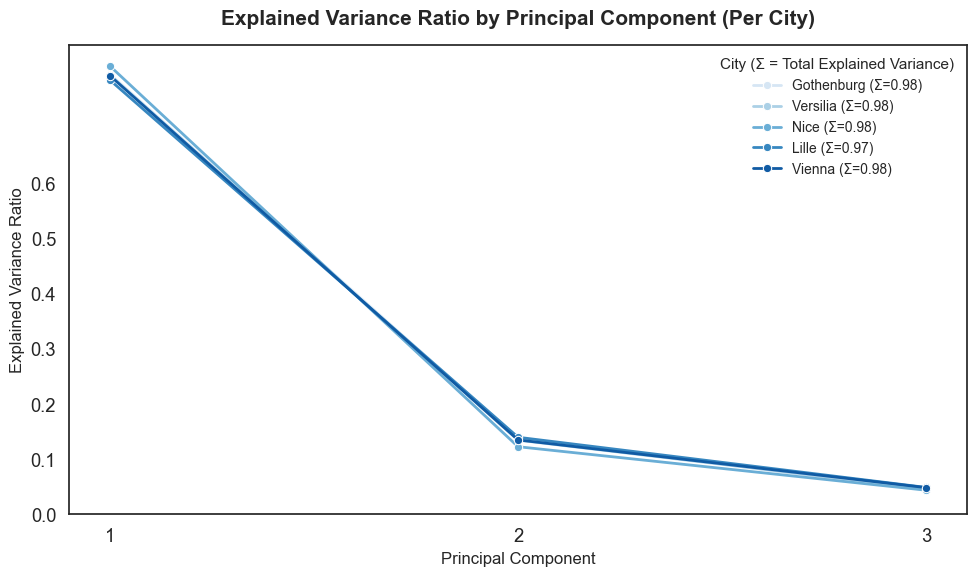

In [9]:
# Print explained variance ratios
print("Explained Variance Ratios by City:")
for city, variance in explained_variance.items():
    print(f"{city}: {variance}")

print("\nTotal Explained Variance by City:")
for city, total_variance in {city: sum(var) for city, var in explained_variance.items()}.items():
    print(f"{city}: {total_variance:.4f}")

# Visualization setup
plt.figure(figsize=(10, 6))
sns.set(style="white", font_scale=1.2)  # clean white background, no grid

# Shades of blue for all cities
blues = sns.color_palette("Blues", n_colors=len(explained_variance))
hue_color_map = dict(zip(explained_variance.keys(), blues))

# Plot each city
for city, variance in explained_variance.items():
    x = np.arange(1, len(variance) + 1)
    sns.lineplot(
        x=x, y=variance,
        marker='o', markersize=6,
        linewidth=2,
        color=hue_color_map[city],
        label=f"{city} (Σ={sum(variance):.2f})"
    )

# Labels, titles, and legend
plt.title('Explained Variance Ratio by Principal Component (Per City)', fontsize=15, weight='bold', pad=15)
plt.xlabel('Principal Component', fontsize=12)
plt.ylabel('Explained Variance Ratio', fontsize=12)
plt.xticks(ticks=range(1, len(next(iter(explained_variance.values()))) + 1))
plt.yticks(np.arange(0, 0.61, 0.1))
plt.legend(
    title="City (Σ = Total Explained Variance)",
    fontsize=10, title_fontsize=11,
    loc='upper right', frameon=False
)
plt.tight_layout()

# Save figure
plt.savefig(
    'YOUR PATH',
    format='png', dpi=300, bbox_inches='tight'
)

plt.show()

#### Create the rotated components

In [10]:
pca_rotated = {}

# Apply varimax rotation to PCA loadings per city
for city_name, loadings in pca_loadings.items():
    rotator = Rotator(method='varimax', normalize=True)
    rotated_loadings = rotator.fit_transform(loadings)

    # Identify ABw columns from the corresponding city's DataFrame
    norm_columns = [col for col in cities[city_name].columns if col.startswith('CB_MB_')]

    # Store rotated loadings as DataFrame
    pca_rotated[city_name] = pd.DataFrame(
        rotated_loadings,
        columns=[f'RC{i + 1}' for i in range(rotated_loadings.shape[1])],
        index=norm_columns
    )

# Combine all cities' rotated components into a single DataFrame
pca_rotated_components = (
    pd.concat(pca_rotated.values(), keys=pca_rotated.keys())
    .reset_index()
    .rename(columns={'level_0': 'city', 'level_1': 'Radius'})
)

#### Plot the rotated components

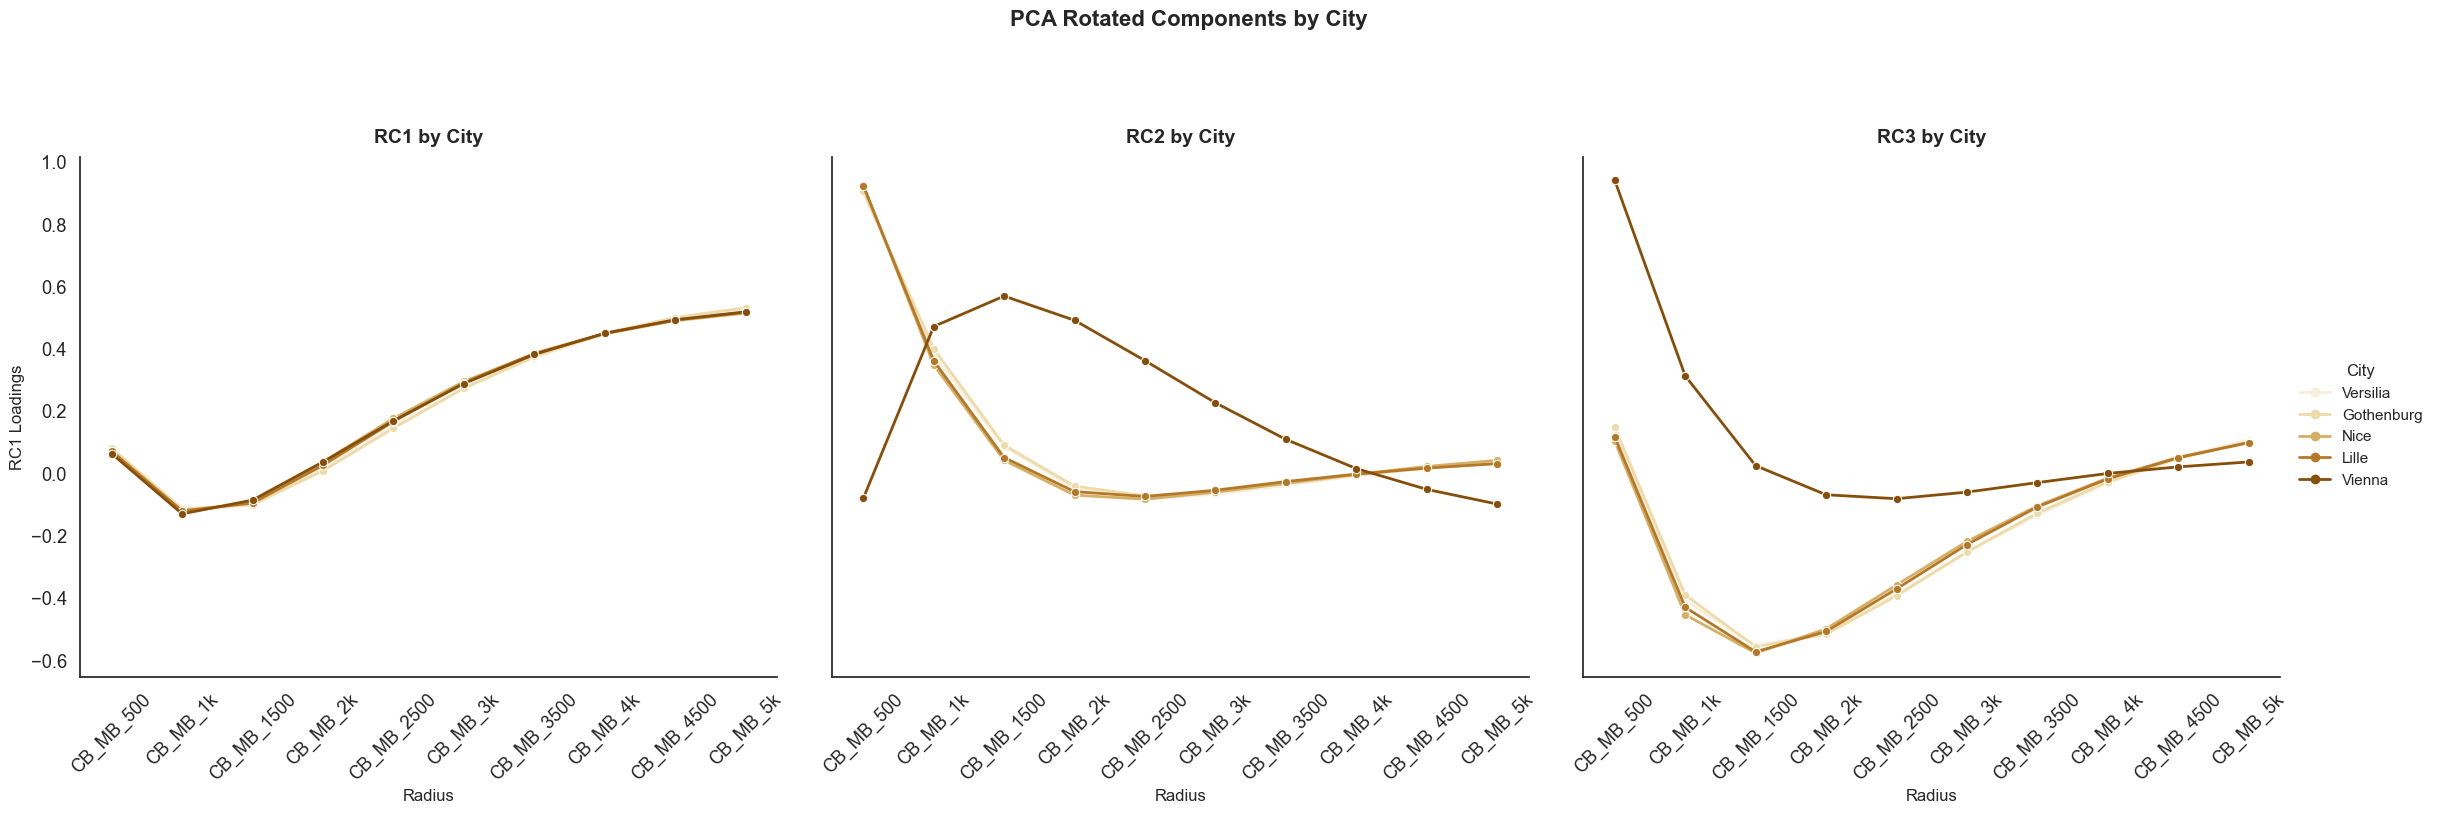

In [11]:
# PCA Rotated Components Visualization
sns.set(style='white', font_scale=1.2)

# Create subplots
fig, axes = plt.subplots(1, 3, figsize=(24, 8), sharey=True)

# Define harmonious shades of brown
browns = sns.color_palette("BrBG", n_colors=10)[:5][::-1]
hue_color_map = dict(zip(['Versilia', 'Gothenburg', 'Nice', 'Lille', 'Vienna'], browns))

# Define reusable plotting function (no per-axis legend)
def plot_pca_component(component, ax, title):
    for city, color in hue_color_map.items():
        city_data = pca_rotated_components[pca_rotated_components['city'] == city]
        sns.lineplot(
            data=city_data, x='Radius', y=component,
            color=color, ax=ax,
            marker='o', markersize=6, linewidth=2
        )
    ax.set_title(title, fontsize=14, weight='bold', pad=10)
    ax.set_xlabel('Radius', fontsize=12)
    ax.set_ylabel(f'{component} Loadings', fontsize=12)
    ax.tick_params(axis='x', rotation=45)
    sns.despine(ax=ax, left=False, bottom=False)

# Plot the three main components
plot_pca_component('RC1', axes[0], 'RC1 by City')
plot_pca_component('RC2', axes[1], 'RC2 by City')
plot_pca_component('RC3', axes[2], 'RC3 by City')

# Global title
plt.suptitle('PCA Rotated Components by City', fontsize=16, weight='bold', y=1.02)

# Single vertical legend, closer to the graph
fig.legend(
    handles=[plt.Line2D([0], [0], color=color, lw=2, marker='o', markersize=6) for color in hue_color_map.values()],
    labels=hue_color_map.keys(),
    loc='center right',
    bbox_to_anchor=(1.02, 0.5),  # move closer to subplots
    fontsize=11, title='City', title_fontsize=12, frameon=False
)

plt.tight_layout(rect=[0, 0, 0.97, 0.95])  # leave small space for legend
plt.savefig(
    'YOUR_PATH',
    dpi=300, bbox_inches='tight', format='png'
)
plt.show()

#### Invert and swap components

In [12]:
pca_results_combined_invertedpca = pca_results_combined.copy()

#Swap
mask = pca_results_combined_invertedpca['city'] == 'Vienna'
temp_pc2 = pca_results_combined_invertedpca.loc[mask, 'PC2'].copy()
pca_results_combined_invertedpca.loc[mask, 'PC2'] = pca_results_combined.loc[mask, 'PC3']
pca_results_combined_invertedpca.loc[mask, 'PC3'] = temp_pc2

# Invert
pca_results_combined_invertedpca.loc[pca_results_combined_invertedpca['city'] == 'Vienna', 'PC3'] *= -1

#### Optional Step:
###### For visualization purposes, if one of the components shows the same silhouette as the others but is mirrored, the solution is to invert the sign (positive or negative) of that component. This will not affect the clustering step.

In [15]:
pca_rotated_components_adjusted = pca_rotated_components.copy()

# Swap
temp_rc2 = pca_rotated_components_adjusted.loc[pca_rotated_components_adjusted['city'] == 'Vienna', 'RC2']
temp_rc3 = pca_rotated_components_adjusted.loc[pca_rotated_components_adjusted['city'] == 'Vienna', 'RC3']

pca_rotated_components_adjusted.loc[pca_rotated_components_adjusted['city'] == 'Vienna', 'RC2'] = temp_rc3
pca_rotated_components_adjusted.loc[pca_rotated_components_adjusted['city'] == 'Vienna', 'RC3'] = temp_rc2

In [16]:
#Function
def adjust_rc_columns(df, city_name, *rc_columns):
    for col in rc_columns:
        df[col] = np.where(df['city'] == city_name, df[col] * -1, df[col])

    return df

# Usage
rc_columns = ['RC3']
pca_rotated_components_adjusted = adjust_rc_columns(pca_rotated_components_adjusted, 'Gothenburg', 'RC3')
#pca_rotated_components_adjusted = adjust_rc_columns(pca_rotated_components_adjusted, 'Vienna', 'RC3')
pca_rotated_components_adjusted = adjust_rc_columns(pca_rotated_components_adjusted, 'Versilia', 'RC3')
pca_rotated_components_adjusted = adjust_rc_columns(pca_rotated_components_adjusted, 'Nice', 'RC3')
pca_rotated_components_adjusted = adjust_rc_columns(pca_rotated_components_adjusted, 'Lille', 'RC3')

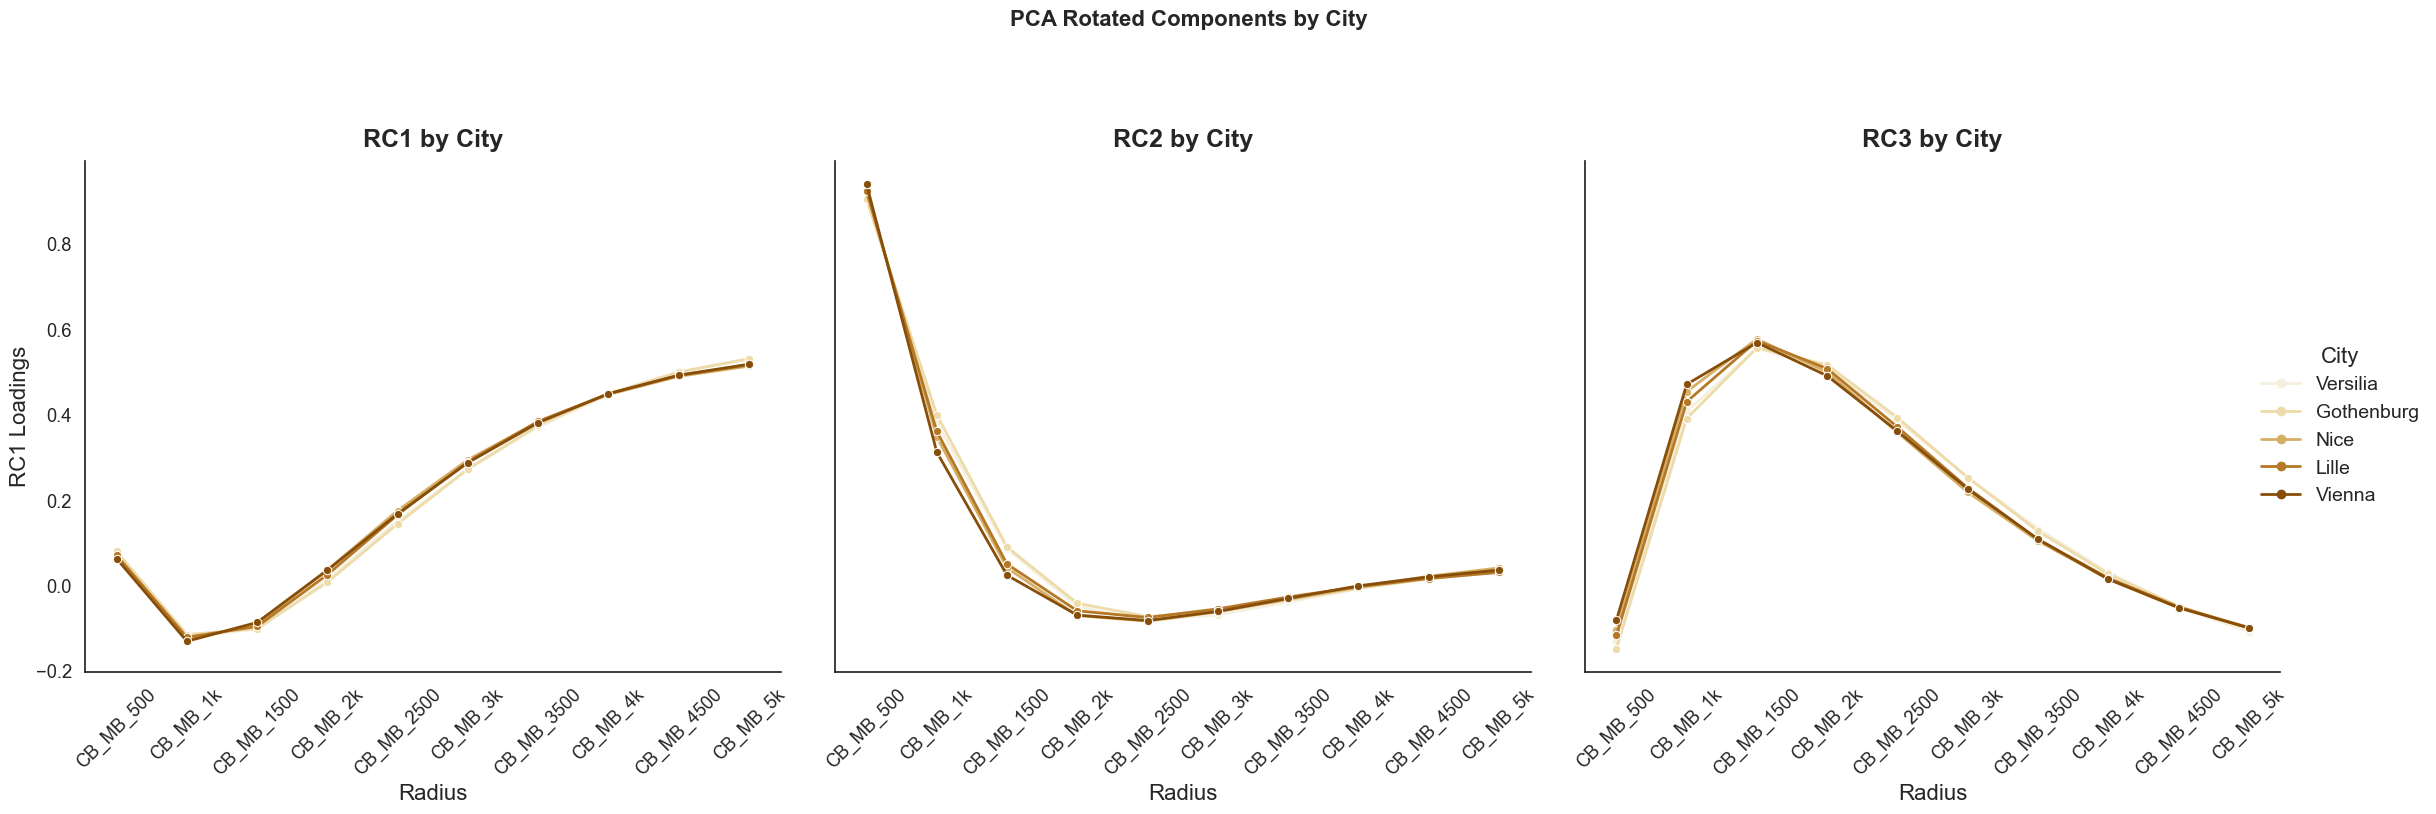

In [17]:
# PCA Rotated Components Visualization
sns.set(style='white', font_scale=1.2)

# Create subplots
fig, axes = plt.subplots(1, 3, figsize=(24, 8), sharey=True)

# Define harmonious shades of brown
browns = sns.color_palette("BrBG", n_colors=10)[:5][::-1]
hue_color_map = dict(zip(['Versilia', 'Gothenburg', 'Nice', 'Lille', 'Vienna'], browns))

# Define reusable plotting function (no per-axis legend)
def plot_pca_component(component, ax, title):
    for city, color in hue_color_map.items():
        city_data = pca_rotated_components_adjusted[pca_rotated_components_adjusted['city'] == city]
        sns.lineplot(
            data=city_data, x='Radius', y=component,
            color=color, ax=ax,
            marker='o', markersize=6, linewidth=2
        )
    ax.set_title(title, fontsize=18, weight='bold', pad=10)
    ax.set_xlabel('Radius', fontsize=16)
    ax.set_ylabel(f'{component} Loadings', fontsize=16)
    ax.tick_params(axis='x', rotation=45)
    sns.despine(ax=ax, left=False, bottom=False)

# Plot the three main components
plot_pca_component('RC1', axes[0], 'RC1 by City')
plot_pca_component('RC2', axes[1], 'RC2 by City')
plot_pca_component('RC3', axes[2], 'RC3 by City')

# Global title
plt.suptitle('PCA Rotated Components by City', fontsize=16, weight='bold', y=1.02)

# Single vertical legend, closer to the graph
fig.legend(
    handles=[plt.Line2D([0], [0], color=color, lw=2, marker='o', markersize=6) for color in hue_color_map.values()],
    labels=hue_color_map.keys(),
    loc='center right',
    bbox_to_anchor=(1.02, 0.5),  # move closer to subplots
    fontsize=14, title='City', title_fontsize=16, frameon=False
)

plt.tight_layout(rect=[0, 0, 0.97, 0.95])  # leave small space for legend
plt.savefig(
    'YOUR PATH',
    dpi=300, bbox_inches='tight', format='png'
)
plt.show()

#### Export the results, results combined and by results by city

In [18]:
# Function filter:
def filter_gdf(gdf, city_name):
    gdf_filtered = gdf[gdf['city'] == city_name]
    return gdf_filtered

got_pca_results = filter_gdf(pca_results_combined, 'Gothenburg')
ver_pca_results = filter_gdf(pca_results_combined, 'Versilia')
nic_pca_results = filter_gdf(pca_results_combined, 'Nice')
lil_pca_results = filter_gdf(pca_results_combined, 'Lille')
vie_pca_results = filter_gdf(pca_results_combined, 'Vienna')

In [19]:
# Function export:
def export(gdf, table_name, schema_name, engine):
    gdf.to_postgis(
        table_name,
        engine,
        schema=schema_name,
        if_exists='replace'
    )
# Export
export(pca_results_combined, 'mbr_sca_1_pca_results_nms_combined_cities_EPSG3857', 's7_paper_foreground_street_networks', engine)
export(got_pca_results, 'mbr_sca_1_pca_results_nms_got_EPSG3857', 's7_paper_foreground_street_networks', engine)
export(ver_pca_results, 'mbr_scal_1_pca_results_nms_ver_EPSG3857', 's7_paper_foreground_street_networks', engine)
export(nic_pca_results, 'mbr_scal_1_pca_results_nms_nic_EPSG3857', 's7_paper_foreground_street_networks', engine)
export(lil_pca_results, 'mbr_scal_1_pca_results_nms_lil_EPSG3857', 's7_paper_foreground_street_networks', engine)
export(vie_pca_results, 'mbr_scal_1_pca_results_nms_lil_EPSG3857', 's7_paper_foreground_street_networks', engine)

## Clustering

#### Check the Silhouette Score

In [25]:
# Define variables
range_n_clusters = list(range(3,10))
sample_pca_results = pca_results_combined_invertedpca[['PC1', 'PC2', 'PC3']].sample(25000, random_state=seed_number)

# Standardize the sample data
scaler = StandardScaler()
sample_pca_results = scaler.fit_transform(sample_pca_results)

# Initialize list to store silhouette scores
silhouette_scores = []
cluster_labels_list = []

# Loop through each number of clusters
for n_clusters in range_n_clusters:
    clusterer = MiniBatchKMeans(n_clusters=n_clusters, random_state=seed_number, batch_size=3072)
    cluster_labels = clusterer.fit_predict(sample_pca_results)

    silhouette_avg = silhouette_score(sample_pca_results, cluster_labels)
    silhouette_scores.append(silhouette_avg)  # Store the average silhouette score
    cluster_labels_list.append(cluster_labels)  # Store cluster labels for each n_clusters
    print(f"For n_clusters = {n_clusters}, the average silhouette_score is : {silhouette_avg:.4f}")

# Create a line plot for silhouette scores
plt.figure(figsize=(10, 6))
sns.lineplot(x=range_n_clusters, y=silhouette_scores, marker='o', color='red')
plt.title('Average Silhouette Score vs Number of Clusters', fontsize=16)
plt.xlabel('Number of Clusters', fontsize=14)
plt.ylabel('Average Silhouette Score', fontsize=14)
plt.xticks(range_n_clusters)  # Set x-ticks to the number of clusters
plt.grid(True)
plt.savefig('YOUR_PATH', format='png', dpi=300, bbox_inches='tight')
plt.show()

For n_clusters = 3, the average silhouette_score is : 0.3337
For n_clusters = 4, the average silhouette_score is : 0.2901


KeyboardInterrupt: 

For n_clusters = 3, the average silhouette_score is : 0.4455
For n_clusters = 4, the average silhouette_score is : 0.4715
For n_clusters = 5, the average silhouette_score is : 0.4095
For n_clusters = 6, the average silhouette_score is : 0.4200
For n_clusters = 7, the average silhouette_score is : 0.4269
For n_clusters = 8, the average silhouette_score is : 0.4226
For n_clusters = 9, the average silhouette_score is : 0.3416


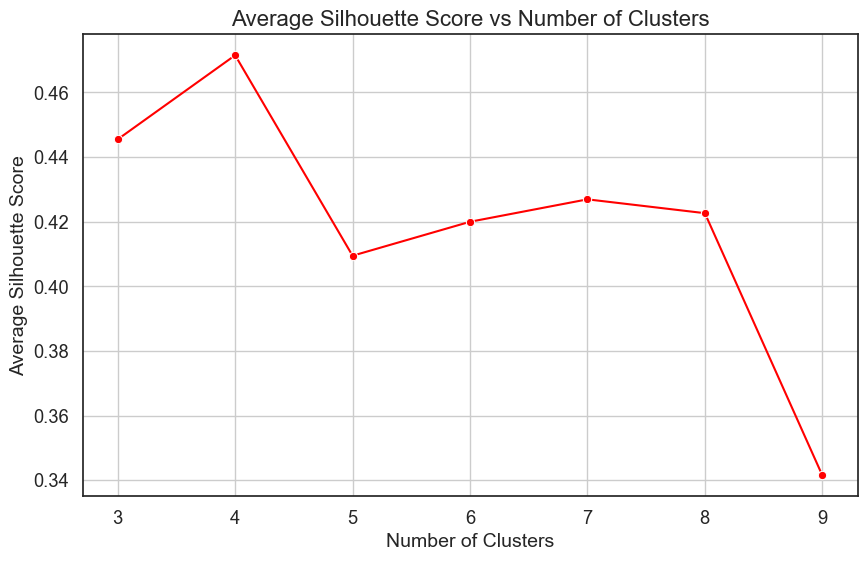

In [39]:
# Define variables
range_n_clusters = list(range(3, 10))
seed_number = 42
scaled_groups = []

# Standardize PCA components by city, keep original columns
for city, group in pca_results_combined.groupby("city"):
    group_scaled = group.copy()
    scaler = StandardScaler()
    group_scaled[['PC1', 'PC2', 'PC3']] = scaler.fit_transform(group_scaled[['PC1', 'PC2', 'PC3']])
    scaled_groups.append(group_scaled)

# Combine all scaled results
scaled_combined = pd.concat(scaled_groups, ignore_index=True)

# Sample from the full dataset, preserving original columns
sample_pca_results = scaled_combined.sample(25000, random_state=seed_number)
sample_features = sample_pca_results[['PC1', 'PC2', 'PC3']]  # features for clustering

# Initialize list to store silhouette scores
silhouette_scores = []
cluster_labels_list = []

# Loop through each number of clusters
for n_clusters in range_n_clusters:
    clusterer = MiniBatchKMeans(n_clusters=n_clusters, random_state=seed_number, batch_size=3072)
    cluster_labels = clusterer.fit_predict(sample_features)

    silhouette_avg = silhouette_score(sample_features, cluster_labels)
    silhouette_scores.append(silhouette_avg)
    cluster_labels_list.append(cluster_labels)
    print(f"For n_clusters = {n_clusters}, the average silhouette_score is : {silhouette_avg:.4f}")

# Create a line plot for silhouette scores
plt.figure(figsize=(10, 6))
sns.lineplot(x=range_n_clusters, y=silhouette_scores, marker='o', color='red')
plt.title('Average Silhouette Score vs Number of Clusters', fontsize=16)
plt.xlabel('Number of Clusters', fontsize=14)
plt.ylabel('Average Silhouette Score', fontsize=14)
plt.xticks(range_n_clusters)
plt.grid(True)
plt.savefig('YOUR_PATH', format='png', dpi=300, bbox_inches='tight')
plt.show()

#### Clusterize using Clara method (K-medoids)

In [20]:
# Do we need to scale the pca here as well?
# Create a copy of the original DataFrame
combined_pca_clustering_results = pca_results_combined_invertedpca.copy()

# Extract relevant columns (adjust column indices as needed)
combined_pca_clustering_results_filtered = combined_pca_clustering_results [['PC1', 'PC2', 'PC3']]  # Selecting columns 12 to 5

# # Testing Scaling: Standardize the sample data
scaler = StandardScaler()
combined_pca_clustering_results_filtered = scaler.fit_transform(combined_pca_clustering_results_filtered)

# Initialize the CLARA model
clara_model = CLARA(n_clusters=4, metric='euclidean', n_sampling=10000, random_state=seed_number)

# Fit the model to your data
clara_model.fit(combined_pca_clustering_results_filtered)

# Get the labels assigned to each point
labels = clara_model.labels_

# Get the cluster centers (medoids)
medoids = clara_model.cluster_centers_

# Add the cluster labels to the original DataFrame (optional)
combined_pca_clustering_results['cluster_4'] = labels

# Plot the table
combined_pca_clustering_results.head()

,city,fid,geometry,id,uv,abw500,abw1k,abw1500,abw2k,abw2500,...,CB_MB_2500,CB_MB_3k,CB_MB_3500,CB_MB_4k,CB_MB_4500,CB_MB_5k,PC1,PC2,PC3,cluster_4
0,Gothenburg,1,"LINESTRING (1342159.842 7883580.812, 1342181.1...",1,148923_2613675388,3030.0,32290.5,72624.50,150848.50,245350.50,...,12.159436,12.904782,12.691311,11.876547,10.693267,9.446758,-0.483343,-0.498364,-0.312176,2
1,Gothenburg,2,"LINESTRING (1342169.171 7883499.833, 1342181.1...",2,148923_2613675332,2869.0,31370.5,70602.50,146965.00,239544.00,...,11.721376,12.558761,12.348099,11.593132,10.436182,9.214429,-0.531493,-0.514123,-0.306305,2
2,Gothenburg,3,"LINESTRING (1345950.739 7898301.149, 1345956.5...",3,162381_5706052174,1876.5,28714.5,93314.75,222719.50,428228.00,...,23.551090,23.801916,27.171503,32.222812,36.236985,37.031848,2.070572,-0.266684,-0.775477,1
3,Gothenburg,4,"LINESTRING (1345947.221 7898257.083, 1345950.7...",4,162381_270591673,1969.0,28880.0,94004.75,224205.00,431086.00,...,23.241443,23.864816,27.240952,32.427808,36.369763,37.056078,2.042183,-0.260114,-0.682504,1
4,Gothenburg,5,"LINESTRING (1345954.679 7898196.095, 1345949.8...",5,162382_360626365,2077.0,8184.5,17485.00,26618.75,37945.25,...,1.942819,1.561242,1.431518,1.328753,1.338794,1.240121,-1.483727,-0.003356,0.100869,0


In [21]:
# Function "filter gdf":
got_clustering_results = filter_gdf(combined_pca_clustering_results, 'Gothenburg')
ver_clustering_results = filter_gdf(combined_pca_clustering_results, 'Versilia')
nic_clustering_results = filter_gdf(combined_pca_clustering_results, 'Nice')
lil_clustering_results = filter_gdf(combined_pca_clustering_results, 'Lille')
vie_clustering_results = filter_gdf(combined_pca_clustering_results, 'Vienna')

In [22]:
# Function reproject the gdf:
def reproject_crs(gdf, crs):
    gdf_reprojected = gdf.to_crs(crs)

    return gdf_reprojected
# Reproject
got_clustering_results_original_projection = reproject_crs(got_clustering_results, 'EPSG:3006')
ver_clustering_results_original_projection = reproject_crs(ver_clustering_results, 'EPSG:3003')
nic_clustering_results_original_projection = reproject_crs(nic_clustering_results, 'EPSG:2154')
lil_clustering_results_original_projection = reproject_crs(lil_clustering_results, 'EPSG:2154')
vie_clustering_results_original_projection = reproject_crs(vie_clustering_results, 'EPSG:31256')

In [30]:
# Function export:
def export(gdf, table_name, schema_name, engine):
    gdf.to_postgis(
        table_name,
        engine,
        schema=schema_name,
        if_exists='replace'
    )
# Function "export":
export(combined_pca_clustering_results, 'mbr_2_cluster_results_nms_combined_cities', 's7_paper_foreground_street_networks', engine)
export(got_clustering_results_original_projection, 'mbr_2_cluster_results_nms_got_3006', 's7_paper_foreground_street_networks', engine)
export(ver_clustering_results_original_projection, 'mbr_2_cluster_results_nms_ver_3003', 's7_paper_foreground_street_networks', engine)
export(nic_clustering_results_original_projection , 'mbr_2_cluster_results_nms_nic_2154', 's7_paper_foreground_street_networks', engine)
export(lil_clustering_results_original_projection , 'mbr_2_cluster_results_nms_lil_2154', 's7_paper_foreground_street_networks', engine)
export(vie_clustering_results_original_projection , 'mbr_2_cluster_results_nms_vie_2154', 's7_paper_foreground_street_networks', engine)

#### Visualize: group the number by zscores, plot the data

In [24]:
# Copy the original DataFrame
combined_pca_clustering_zscore_results = combined_pca_clustering_results.copy()

# Define the prefixes for z-score scaling
prefixes = ['CB_MB_', 'abw']

# Initialize the scaler
scaler = StandardScaler()

# Iterate through each prefix to scale and add z-score columns
for prefix in prefixes:
    # Filter columns starting with the current prefix
    selected_columns = [col for col in combined_pca_clustering_results.columns if col.startswith(prefix)]

    # Fit and transform the selected columns
    zscore_values = scaler.fit_transform(combined_pca_clustering_results[selected_columns])

    # Create a DataFrame with the scaled values
    zscore_df = pd.DataFrame(zscore_values, columns=[f'zscore_{col}' for col in selected_columns], index=combined_pca_clustering_results.index)

    # Add the z-score columns back to the original DataFrame
    combined_pca_clustering_results = pd.concat([combined_pca_clustering_results, zscore_df], axis=1)

# Display the updated DataFrame with z-scores
combined_pca_clustering_results.head()

,city,fid,geometry,id,uv,abw500,abw1k,abw1500,abw2k,abw2500,...,zscore_abw500,zscore_abw1k,zscore_abw1500,zscore_abw2k,zscore_abw2500,zscore_abw3k,zscore_abw3500,zscore_abw4k,zscore_abw4500,zscore_abw5k
0,Gothenburg,1,"LINESTRING (1342159.842 7883580.812, 1342181.1...",1,148923_2613675388,3030.0,32290.5,72624.50,150848.50,245350.50,...,-0.114469,0.267764,0.044902,0.012869,-0.046812,-0.113850,-0.162650,-0.198161,-0.226004,-0.244025
1,Gothenburg,2,"LINESTRING (1342169.171 7883499.833, 1342181.1...",2,148923_2613675332,2869.0,31370.5,70602.50,146965.00,239544.00,...,-0.143620,0.242386,0.027664,-0.001189,-0.057501,-0.122039,-0.169120,-0.203185,-0.230015,-0.247286
2,Gothenburg,3,"LINESTRING (1345950.739 7898301.149, 1345956.5...",3,162381_5706052174,1876.5,28714.5,93314.75,222719.50,428228.00,...,-0.323321,0.169119,0.221285,0.273053,0.289828,0.338344,0.366693,0.375069,0.325850,0.259130
3,Gothenburg,4,"LINESTRING (1345947.221 7898257.083, 1345950.7...",4,162381_270591673,1969.0,28880.0,94004.75,224205.00,431086.00,...,-0.306573,0.173684,0.227168,0.278430,0.295089,0.343004,0.370706,0.378469,0.328899,0.261740
4,Gothenburg,5,"LINESTRING (1345954.679 7898196.095, 1345949.8...",5,162382_360626365,2077.0,8184.5,17485.00,26618.75,37945.25,...,-0.287018,-0.397208,-0.425161,-0.436860,-0.428603,-0.416655,-0.403856,-0.393295,-0.381467,-0.371074


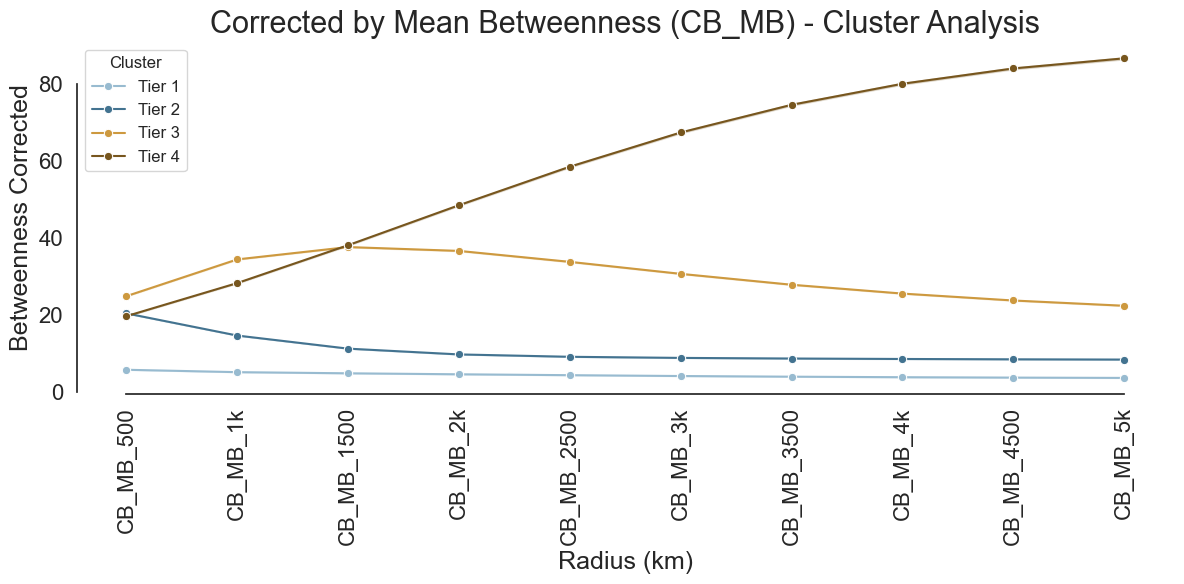

In [25]:
# Define custom colors for each cluster (using cluster names)
cluster_palette = {
    'Tier 1': '#98bbd0',
    'Tier 2': '#437390',
    'Tier 3': '#cd993f',
    'Tier 4': '#77561e'
}

# Define cluster names
cluster_names = {
    2: 'Tier 1',
    0: 'Tier 2',
    1: 'Tier 3',
    3: 'Tier 4'
}

# Map cluster IDs to names in the main DataFrame
combined_pca_clustering_results['cluster_name'] = combined_pca_clustering_results['cluster_4'].map(cluster_names)

# Filter the columns that start with 'zscore_abw'
zscore_columns = [col for col in combined_pca_clustering_results.columns if col.startswith('CB_MB')]

# Reshape the DataFrame for line plotting
melted_zscore = combined_pca_clustering_results.melt(
    id_vars=['cluster_name'],  # use the named clusters
    value_vars=zscore_columns,
    var_name='zscore_variable',
    value_name='value'
)

# Set the style of the visualization
sns.set(style='white')  # clean background, no grid

# Create the line plot with ordered legend
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=melted_zscore,
    x='zscore_variable',
    y='value',
    hue='cluster_name',             # use the names
    hue_order=['Tier 1', 'Tier 2', 'Tier 3', 'Tier 4'],  # enforce hierarchy
    marker='o',
    palette=cluster_palette        # apply the named colors
)

# Customize the plot
plt.title('Corrected by Mean Betweenness (CB_MB) - Cluster Analysis', fontsize=22)
plt.xlabel('Radius (km)', fontsize=18)
plt.ylabel('Betweenness Corrected', fontsize=18)
plt.xticks(rotation=90, fontsize=16)
plt.yticks(fontsize=16)
plt.legend(title='Cluster', fontsize=12, loc='upper left')

# Remove grid
plt.grid(False)
sns.despine(trim=True)

# Show and save the plot
plt.tight_layout()
plt.savefig(
    'YOUR_PATH',
    format='png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

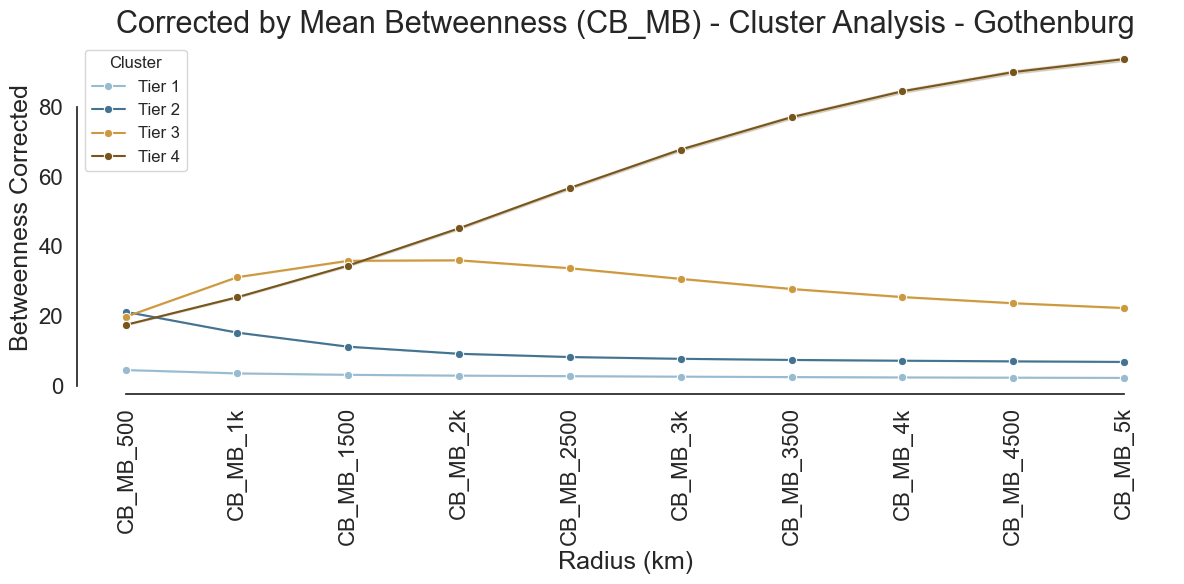

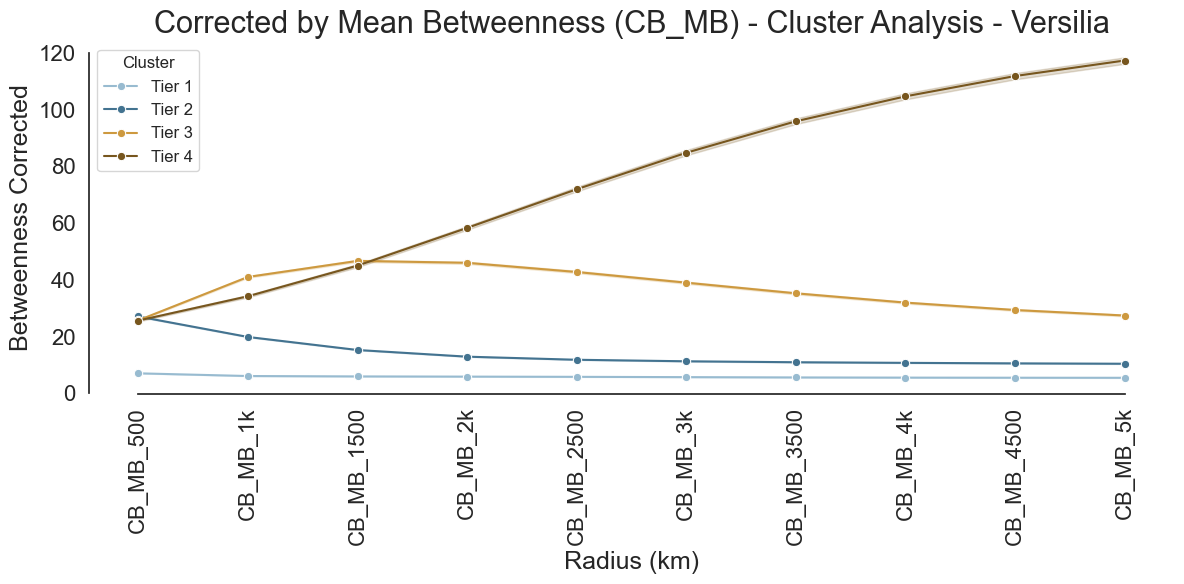

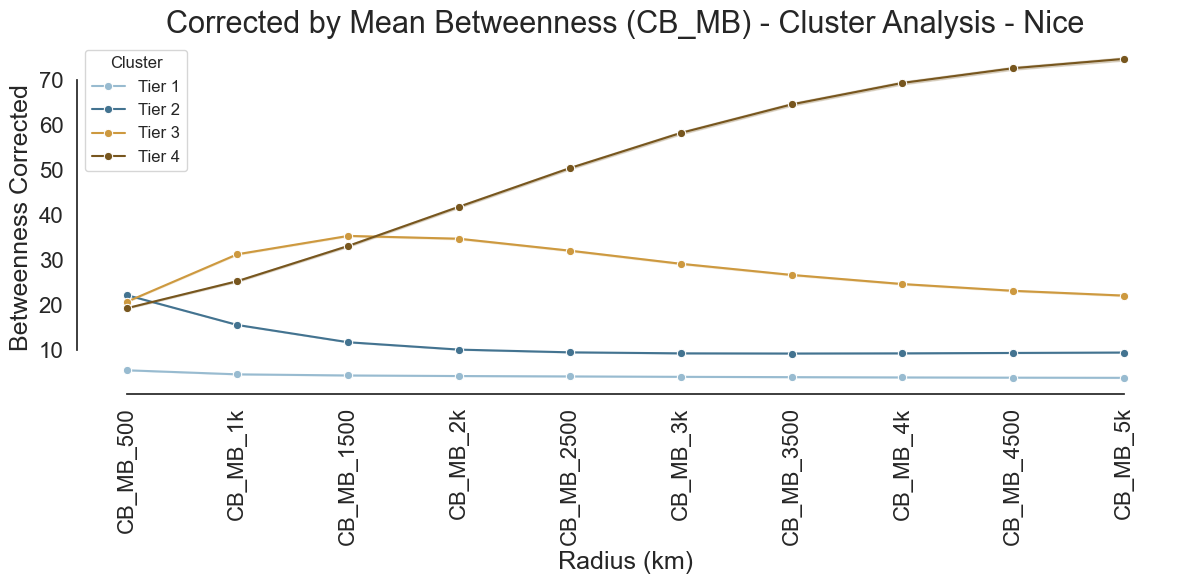

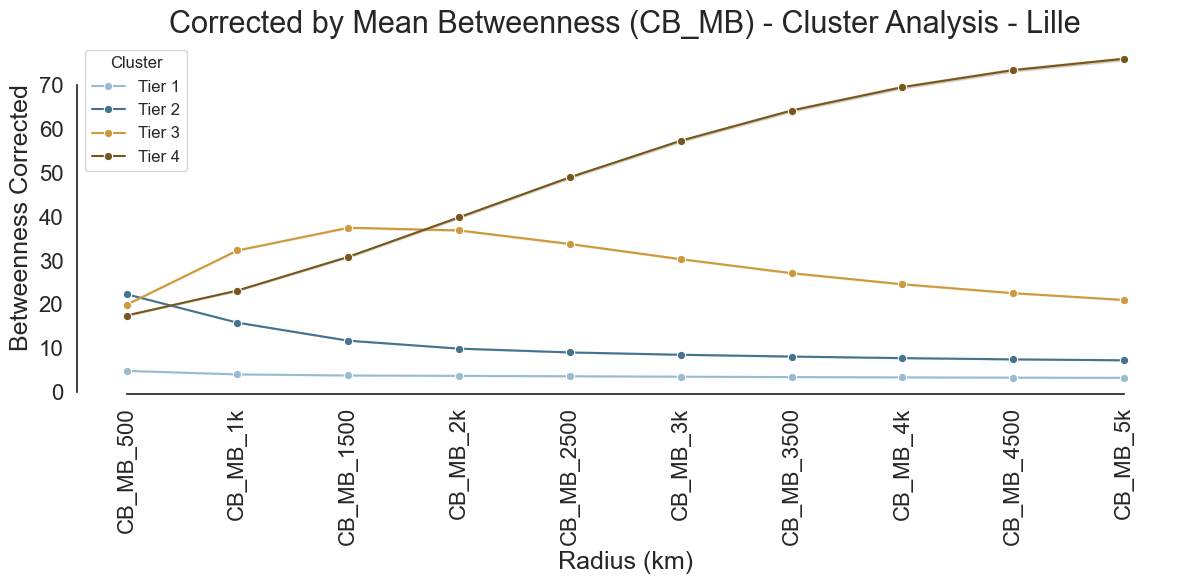

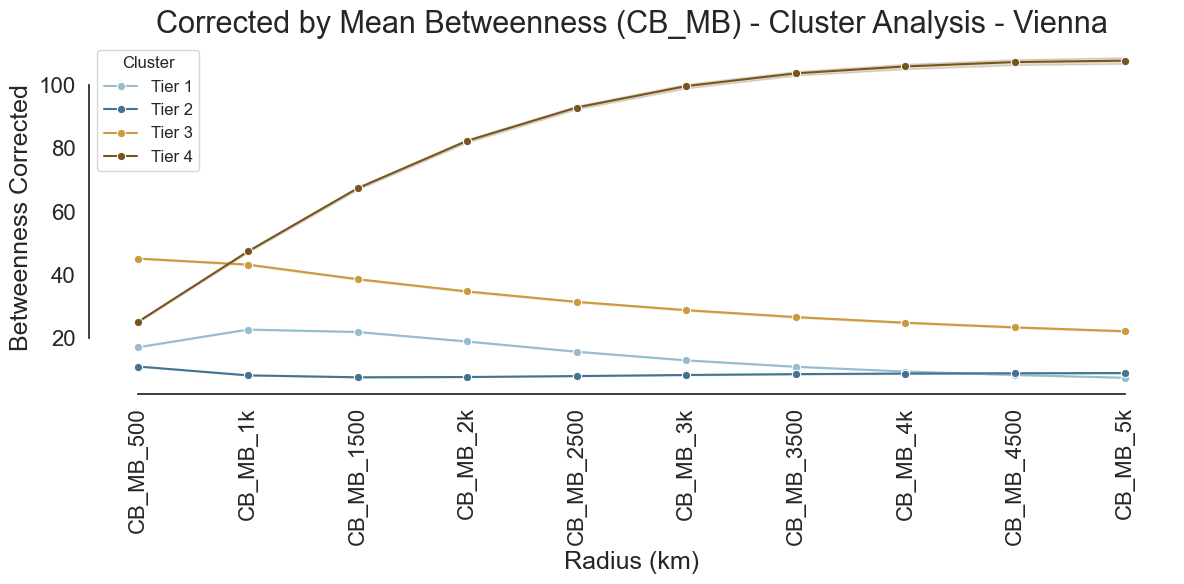

In [26]:
# Define custom colors for each cluster (using cluster names)
cluster_palette = {
    'Tier 1': '#98bbd0',
    'Tier 2': '#437390',
    'Tier 3': '#cd993f',
    'Tier 4': '#77561e'
}

# Define cluster names
cluster_names = {
    2: 'Tier 1',
    0: 'Tier 2',
    1: 'Tier 3',
    3: 'Tier 4'
}

# Map cluster IDs to names in the main DataFrame
combined_pca_clustering_results['cluster_name'] = combined_pca_clustering_results['cluster_4'].map(cluster_names)

# Filter the columns that start with 'zscore_abw'
norm_columns = [col for col in combined_pca_clustering_results.columns if col.startswith('CB_MB')]

# Loop through each city and create a plot
for city in combined_pca_clustering_results['city'].unique():
    city_data = combined_pca_clustering_results[combined_pca_clustering_results['city'] == city]

    # Melt the DataFrame for plotting
    melted_no_scaling = city_data.melt(
        id_vars=['cluster_name'],  # use the mapped names
        value_vars=norm_columns,
        var_name='norm_variable',
        value_name='value'
    )

    # Set the style
    sns.set(style='white')  # clean white background

    # Create the line plot
    plt.figure(figsize=(12, 6))
    sns.lineplot(
        data=melted_no_scaling,
        x='norm_variable',
        y='value',
        hue='cluster_name',  # use the names for hue
        hue_order=['Tier 1', 'Tier 2', 'Tier 3', 'Tier 4'],  # enforce hierarchy
        marker='o',
        palette=cluster_palette
    )

    # Customize the plot
    plt.title(f'Corrected by Mean Betweenness (CB_MB) - Cluster Analysis - {city}', fontsize=22)
    plt.xlabel('Radius (km)', fontsize=18)
    plt.ylabel('Betweenness Corrected', fontsize=18)
    plt.xticks(rotation=90, fontsize=16)
    plt.yticks(fontsize=16)
    plt.legend(title='Cluster', fontsize=12, loc='upper left')  # force legend location

    # Remove the grid
    plt.grid(False)
    sns.despine(trim=True)

    # Save the figure
    plt.tight_layout()
    output_path = f'YOUR_PATH_{city}'
    plt.savefig(output_path, format='png', dpi=300, bbox_inches='tight')
    plt.show()

In [27]:
# Function "filter gdf":
got_clustering_results = filter_gdf(combined_pca_clustering_results, 'Gothenburg')
ver_clustering_results = filter_gdf(combined_pca_clustering_results, 'Versilia')
nic_clustering_results = filter_gdf(combined_pca_clustering_results, 'Nice')
lil_clustering_results = filter_gdf(combined_pca_clustering_results, 'Lille')
vie_clustering_results = filter_gdf(combined_pca_clustering_results, 'Vienna')

In [28]:
# Reproject
got_clustering_results_original_projection = reproject_crs(got_clustering_results, 'EPSG:3006')
ver_clustering_results_original_projection = reproject_crs(ver_clustering_results, 'EPSG:3003')
nic_clustering_results_original_projection = reproject_crs(nic_clustering_results, 'EPSG:2154')
lil_clustering_results_original_projection = reproject_crs(lil_clustering_results, 'EPSG:2154')
vie_clustering_results_original_projection = reproject_crs(vie_clustering_results, 'EPSG:31256')

In [29]:
# Function "export":
export(combined_pca_clustering_results, 'mbr_scal_3_zcores_nms_combined_cities_EPSG3857', 's7_paper_foreground_street_networks', engine)
export(got_clustering_results_original_projection, 'mbr_scal_3_zcores_nms_got_EPSG3006', 's7_paper_foreground_street_networks', engine)
export(ver_clustering_results_original_projection, 'mbr_scal_3_zcores_nms_ver_EPSG3003', 's7_paper_foreground_street_networks', engine)
export(nic_clustering_results_original_projection , 'mbr_scal_3_zcores_nms_nic_EPSG2154', 's7_paper_foreground_street_networks', engine)
export(lil_clustering_results_original_projection , 'mbr_scal_3_zcores_nms_lil_EPSG2154', 's7_paper_foreground_street_networks', engine)
export(vie_clustering_results_original_projection , 'mbr_scal_3_zcores_nms_vie_EPSG2154', 's7_paper_foreground_street_networks', engine)